## 1. Import library dan pengaturan

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_RAW = ROOT / "dataset_raw"
SEGMENTASI = ROOT / "data" / "segmentasi"      # citra berwarna hasil GrabCut (notebook 03)
MASK = ROOT / "data" / "mask"                  # mask hitam-putih hasil GrabCut (notebook 03)
HASIL = ROOT / "hasil" / "ekstraksi_fitur"

KELAS = ["logam", "paper", "plastic"]
LEVEL = 16             # jumlah tingkat abu-abu untuk GLCM
JARAK = 1              # jarak antar piksel
# Sudut dan selisih posisi (baris, kolom) pasangan piksel
ARAH = {0: (0, 1), 45: (-1, 1), 90: (-1, 0), 135: (-1, -1)}
JUMLAH_CONTOH = 2      # contoh per kelas yang ditampilkan

## 2. Fungsi ekstraksi fitur GLCM

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def glcm_satu_arah(q, objek, dy, dx):
    """GLCM satu arah. Pasangan dihitung hanya jika kedua piksel berada di dalam mask."""
    h, w = q.shape
    # piksel asal (a) dan piksel tetangga (b) pada jarak (dy, dx)
    a = q[max(0, -dy):h - max(0, dy), max(0, -dx):w - max(0, dx)]
    b = q[max(0, dy):h - max(0, -dy), max(0, dx):w - max(0, -dx)]
    ma = objek[max(0, -dy):h - max(0, dy), max(0, -dx):w - max(0, dx)]
    mb = objek[max(0, dy):h - max(0, -dy), max(0, dx):w - max(0, -dx)]
    sah = ma & mb                                           # pasangan sah: dua-duanya di dalam objek
    pasangan = a[sah].astype(int) * LEVEL + b[sah]
    P = np.bincount(pasangan, minlength=LEVEL * LEVEL).reshape(LEVEL, LEVEL).astype(np.float64)
    P = P + P.T                                             # simetris
    return P / P.sum() if P.sum() > 0 else None             # normalisasi jadi peluang


def fitur_dari_glcm(P):
    """Contrast, homogeneity, energy, entropy dari satu GLCM yang sudah dinormalisasi."""
    i, j = np.indices(P.shape)
    return np.array([(P * (i - j) ** 2).sum(),               # contrast
                     (P / (1 + (i - j) ** 2)).sum(),         # homogeneity
                     np.sqrt((P ** 2).sum()),                # energy (akar dari ASM)
                     -(P[P > 0] * np.log2(P[P > 0])).sum()]) # entropy


def fitur_tekstur(citra_warna, mask):
    """Langkah 2-4: grayscale -> 16 level -> GLCM 4 arah (hanya dalam mask) -> rata-rata fitur."""
    gray = cv2.cvtColor(citra_warna, cv2.COLOR_BGR2GRAY)
    q = (gray // (256 // LEVEL)).astype(np.int64)           # tingkat abu-abu 0 .. 15
    objek = mask > 0
    ys, xs = np.where(objek)                                # potong ke kotak objek agar lebih cepat
    potong = (slice(ys.min(), ys.max() + 1), slice(xs.min(), xs.max() + 1))
    q, objek = q[potong], objek[potong]

    hasil = []
    for sudut, (dy, dx) in ARAH.items():
        P = glcm_satu_arah(q, objek, dy * JARAK, dx * JARAK)
        if P is not None:
            hasil.append(fitur_dari_glcm(P))
    if not hasil:
        return None
    rata = np.mean(hasil, axis=0)                           # rata-rata empat arah
    return dict(kontras=rata[0], homogenitas=rata[1], energi=rata[2], entropi=rata[3])

## 3. Hitung fitur semua foto dan simpan ke CSV

In [3]:
tabel = pd.read_csv(ROOT / "hasil" / "praproses" / "praproses.csv")

baris, dilewati = [], []
for r in tabel.itertuples():
    nama_png = r.nama_baru.replace(".jpg", ".png")
    citra = baca(SEGMENTASI / r.kelas / nama_png)
    mask = baca(MASK / r.kelas / nama_png, gray=True)
    if citra is None or mask is None or not mask.any():
        dilewati.append(r.nama_baru)          # segmentasi gagal, tidak ada objek untuk dihitung
        continue
    f = fitur_tekstur(citra, mask)
    if f is None:
        dilewati.append(r.nama_baru)
        continue
    baris.append(dict(nama=r.nama_baru, kelas=r.kelas, **f))

fitur = pd.DataFrame(baris, columns=["nama", "kelas", "kontras", "homogenitas", "energi", "entropi"])
HASIL.mkdir(parents=True, exist_ok=True)
fitur.to_csv(HASIL / "fitur_citra.csv", index=False)
print(f"Fitur dihitung untuk {len(fitur)} foto, dilewati {len(dilewati)} foto (segmentasi gagal).")
if dilewati:
    print("Dilewati:", dilewati)

Fitur dihitung untuk 394 foto, dilewati 0 foto (segmentasi gagal).


## 4. Citra asli, hasil segmentasi berwarna, mask, dan tabel fitur



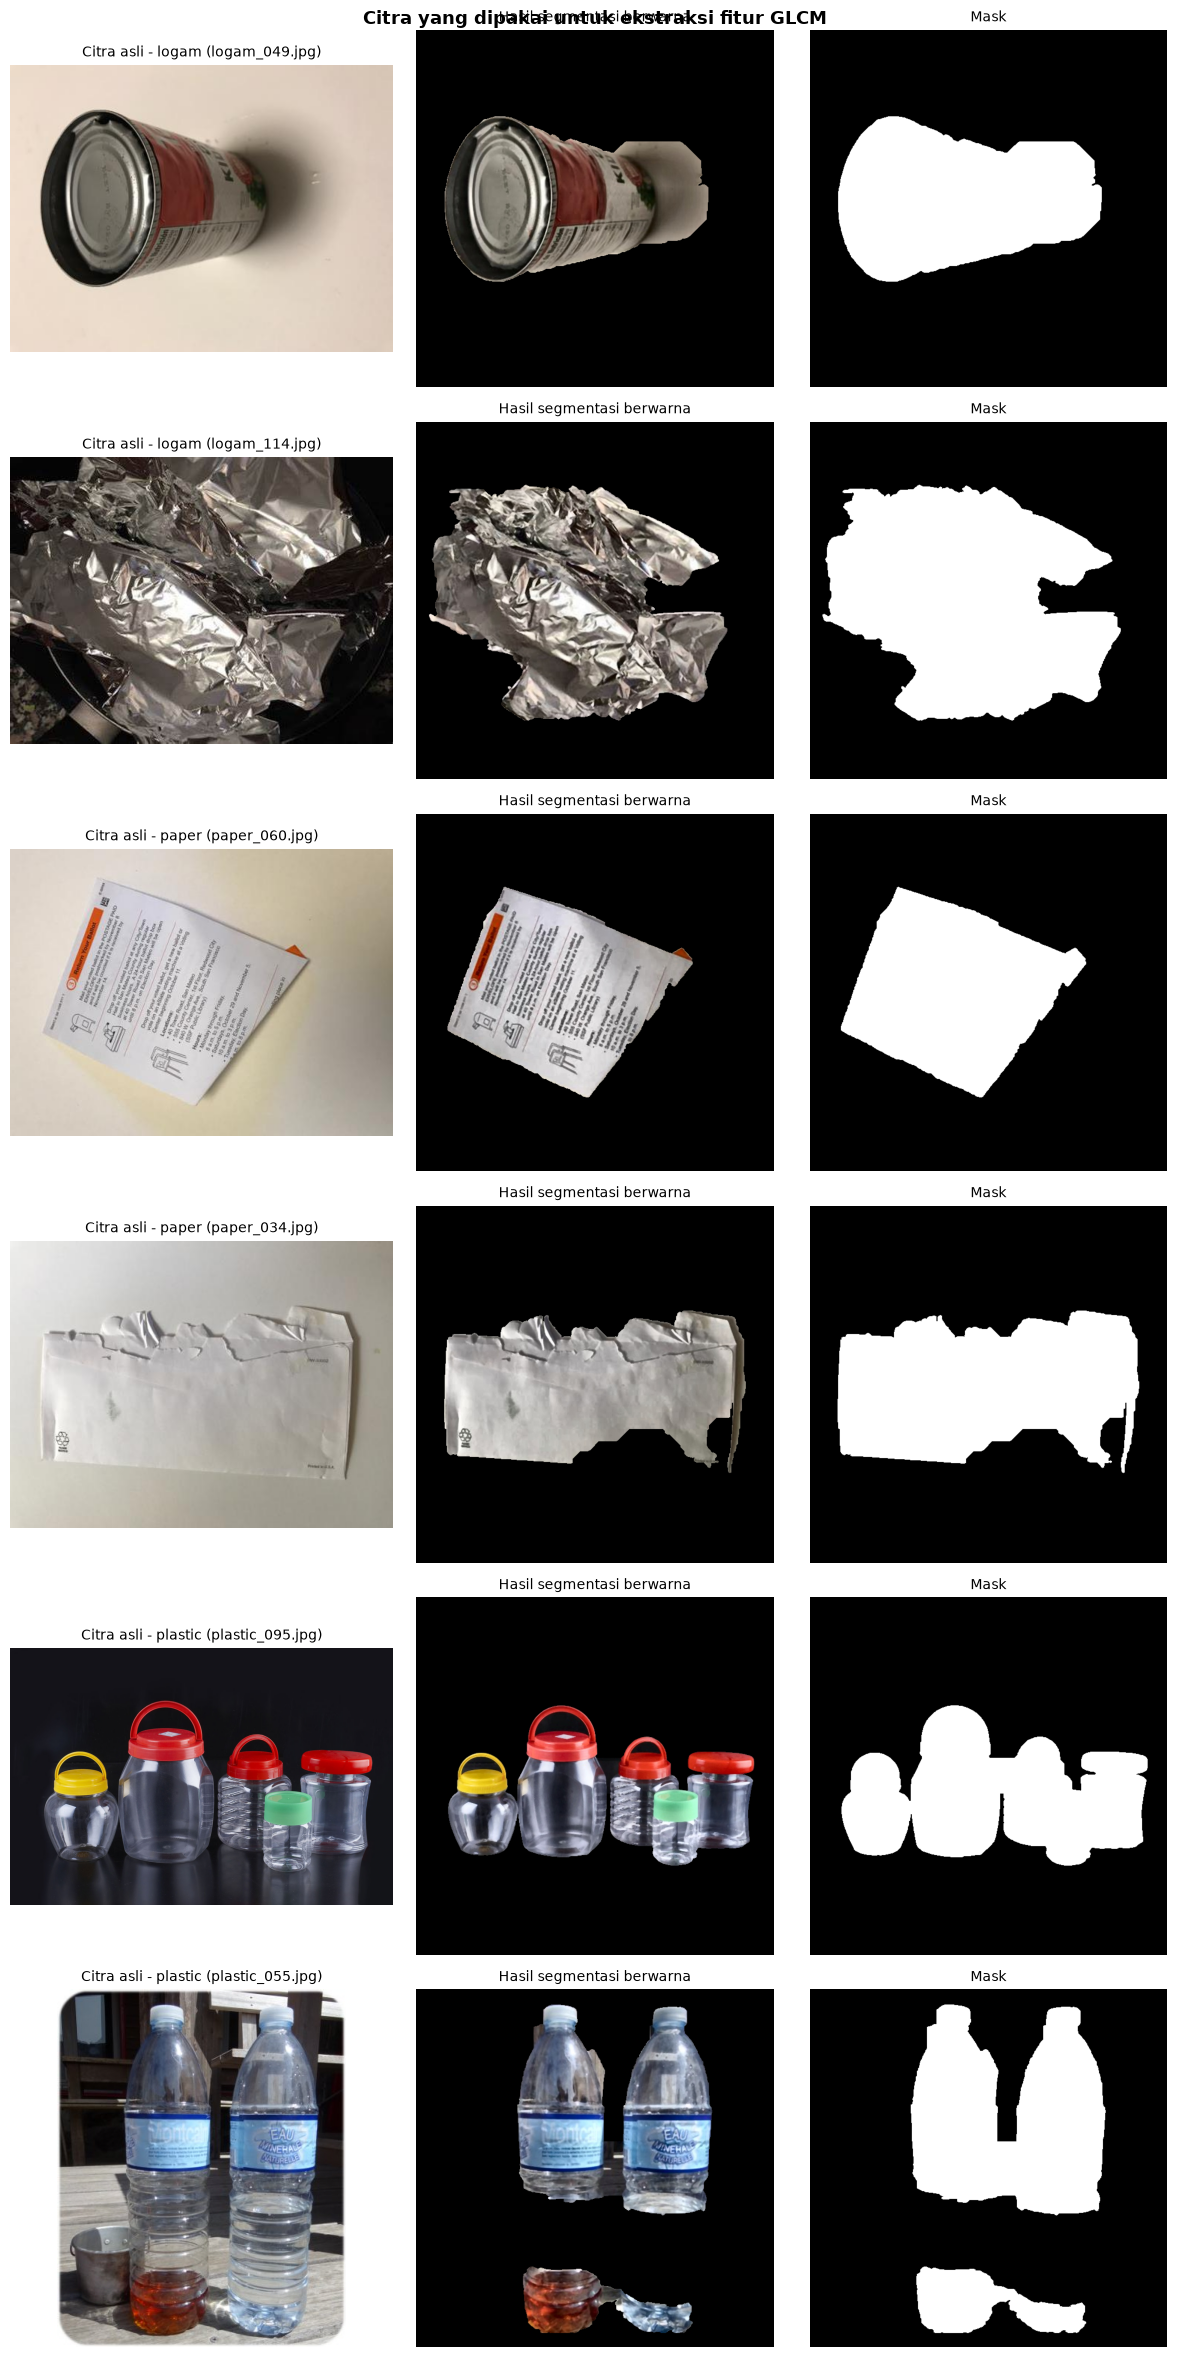

Tabel fitur contoh di atas:


,kelas,kontras,homogenitas,energi,entropi
nama,,,,,
logam_049.jpg,logam,0.9636,0.8231,0.2205,5.0980
logam_114.jpg,logam,1.8615,0.7039,0.1600,5.9598
paper_060.jpg,paper,1.7949,0.7580,0.2744,4.9212
paper_034.jpg,paper,0.4775,0.8879,0.3157,4.1477
plastic_095.jpg,plastic,1.1159,0.7894,0.1824,5.5251
plastic_055.jpg,plastic,0.9880,0.7745,0.1831,5.4941


In [4]:
if fitur.empty:
    raise ValueError("Tidak ada foto yang berhasil disegmentasi. Periksa notebook 03.")

contoh = pd.concat([g.sample(min(JUMLAH_CONTOH, len(g)), random_state=1) for _, g in fitur.groupby("kelas")])
info = tabel.set_index("nama_baru")

fig, ax = plt.subplots(len(contoh), 3, figsize=(12, 4 * len(contoh)), squeeze=False)
for i, r in enumerate(contoh.itertuples()):
    nama_png = r.nama.replace(".jpg", ".png")
    asli = baca(DATASET_RAW / r.kelas / info.loc[r.nama, "nama_asli"])
    citra = baca(SEGMENTASI / r.kelas / nama_png)
    mask = baca(MASK / r.kelas / nama_png, gray=True)
    ax[i, 0].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB))
    ax[i, 0].set_title(f"Citra asli - {r.kelas} ({r.nama})", fontsize=10)
    ax[i, 1].imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    ax[i, 1].set_title("Hasil segmentasi berwarna", fontsize=10)
    ax[i, 2].imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax[i, 2].set_title("Mask", fontsize=10)
    for a in ax[i]:
        a.axis("off")
fig.suptitle("Citra yang dipakai untuk ekstraksi fitur GLCM", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(HASIL / "contoh_ekstraksi_fitur.png", dpi=120)
plt.show()

print("Tabel fitur contoh di atas:")
display(contoh.set_index("nama").round(4))

## 5. Rata-rata fitur per kelas


In [5]:
display(fitur.drop(columns="nama").groupby("kelas").mean().round(4))

,kontras,homogenitas,energi,entropi
kelas,,,,
logam,1.5385,0.7659,0.2095,5.4061
paper,1.4407,0.7885,0.2627,4.8830
plastic,1.0980,0.8034,0.2417,4.9909
